# Disease Classification with MultiMIL

- Creator: Arpit Merchant (am84@sanger.ac.uk)
- Date of Creation: 22.12.2025
- Date of Last Modification: 8.12.2025 (by Arpit Merchant; am84@sanger.ac.uk)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import re
import os
import sys
import yaml
import tempfile
import shutil
import pickle
import warnings
from tqdm import tqdm
from collections import Counter
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Union, Literal

import numpy as np
import scanpy as sc
import pandas as pd
import anndata as ad
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import classification_report

import scvi
import multimil as mtm

import torch

warnings.filterwarnings("ignore")

/software/cellgen/team361/am84/envs/multimil/lib/python3.10/site-packages/lightning_fabric/__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)
Global seed set to 0
/software/cellgen/team361/am84/envs/multimil/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# https://stackoverflow.com/questions/50506076/is-there-an-efficient-way-to-store-2d-plots-as-a-vector-graphic-in-python

import matplotlib as mpl

mpl.use('svg')
new_rc_params = {
    "font.size": 9,
    "font.serif": [],
    "svg.fonttype": 'none'} # to store text as text, not as path
mpl.rcParams.update(new_rc_params)

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
scvi.settings.seed = 0
NUM_CORES = int(os.environ.get("LSB_DJOB_NUMPROC",1))
print(NUM_CORES)

# Set device
if not torch.cuda.is_available():
    device = torch.device('cpu')
else:
    device = torch.device('cuda:0')
    torch.cuda.set_device(device)
print(device)

Global seed set to 0


4
cuda:0


# Helper Functions

In [5]:
def create_anndata_from_embeddings(
        embeddings: np.ndarray,
        adata_metadata: ad.AnnData,
        sample_key: str,
        classification_key: str
    ) -> ad.AnnData:
    """
    Create AnnData object with embeddings in X and metadata in obs.
    
    Parameters:
    -----------
    embeddings: np.ndarray
        Embeddings array of shape (n_cells, embedding_dim).
    adata_metadata: ad.AnnData
        AnnData object containing metadata (must have cell_id in obs).
    sample_key: str
        Key in adata_metadata.obs for sample grouping.
    classification_key: str
        Key in adata_metadata.obs for classification labels.
        
    Returns:
    -------
    adata: ad.AnnData
        AnnData object with embeddings in X and metadata in obs.
    """
    # Get cell IDs from metadata
    cell_ids = adata_metadata.obs['cell_id'].tolist()
    
    # Ensure embeddings and metadata have same number of cells
    assert len(embeddings) == len(cell_ids), \
        f"Mismatch: {len(embeddings)} embeddings but {len(cell_ids)} cells"
    
    # Create AnnData with embeddings in X
    adata = ad.AnnData(X=embeddings.astype(np.float32))
    
    # Copy relevant metadata
    adata.obs['cell_id'] = cell_ids
    adata.obs[sample_key] = adata_metadata.obs[sample_key].values
    adata.obs[classification_key] = adata_metadata.obs[classification_key].values
    
    # Copy other metadata columns if needed
    for col in adata_metadata.obs.columns:
        if col not in adata.obs.columns:
            adata.obs[col] = adata_metadata.obs[col].values

    # ============================================================================
    # 3. Setup AnnData for MILClassifier
    # ============================================================================
    mtm.model.MILClassifier.setup_anndata(
        adata,
        categorical_covariate_keys=[sample_key, classification_key],
        continuous_covariate_keys=None,
    )

    print("AnnData setup complete!")

    return adata

In [6]:
def train_MIL(
        adata,
        sample_key,
        classification_key
    ):
    model = mtm.model.MILClassifier(
        adata=adata,
        sample_key=sample_key,
        classification=[classification_key],
        dropout=0.1,
        n_layers_classifier=2,
        n_hidden_classifier=adata.shape[1],
        n_layers_cell_aggregator=1,
        n_hidden_cell_aggregator=adata.shape[1],
        attn_dim=16,
        scoring='attn',
        normalization="layer",
    )

    print("Model created!")    
    
    runner = model.train(
        max_epochs=20,
        lr=1e-5,
        train_size=0.8,
        validation_size=0.2,
        batch_size=256,
        early_stopping=True,
    )

    print("Training complete!")
    
    model.plot_losses()
    
    return model

In [7]:
def evaluate_model(
        trained_model,
        test_adata,
        classification_key,
    ):
    # For Test Set
    test_model = mtm.model.MILClassifier.load_query_data(test_adata, trained_model)
    test_model.get_model_output(batch_size=256)    

    pred_col = f"predicted_{classification_key}"
    test_pred = test_adata.obs[pred_col].cat.codes.values if hasattr(test_adata.obs[pred_col], 'cat') else test_adata.obs[pred_col].values
    test_true = test_adata.obs[classification_key].cat.codes.values if hasattr(test_adata.obs[classification_key], 'cat') else test_adata.obs[classification_key].values

    test_accuracy = accuracy_score(test_true, test_pred)
    test_f1 = f1_score(test_true, test_pred, average='weighted')

    print(f"Test Accuracy: {test_accuracy:.4f}")
    print(f"Test F1: {test_f1:.4f}")
    print(classification_report(test_true, test_pred))
    
    return test_accuracy, test_f1

In [8]:
def single_train_test_pipeline(
        sample_key,
        classification_key,
        dataset_name,
        model_name,
        outer_fold,
    ):
    ##################################
    # 1. Prepare Train-Val Adata
    ##################################

    trainval_adata_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/{dataset_name}/data/outer-fold_{outer_fold}/train.h5ad")
    trainval_adata = sc.read_h5ad(trainval_adata_path)

    # Load embeddings
    trainval_emb_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/{dataset_name}/model_artifacts/{model_name}-zeroshot/outer-fold_{outer_fold}/train_features.npy")
    trainval_embeddings = np.load(trainval_emb_path)
    
    trainval_adata = create_anndata_from_embeddings(
            trainval_embeddings,
            trainval_adata,
            sample_key,
            classification_key
        )

    print(f"Trainval Adata Shape: {trainval_adata.shape}")

    ##################################
    # 2. Prepare Test Adata
    ##################################
    
    test_adata_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/{dataset_name}/data/outer-fold_{outer_fold}/test.h5ad")
    test_adata = sc.read_h5ad(test_adata_path)

    # Load embeddings
    test_emb_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/{dataset_name}/model_artifacts/{model_name}-zeroshot/outer-fold_{outer_fold}/test_features.npy")
    test_embeddings = np.load(test_emb_path)

    test_adata = create_anndata_from_embeddings(
        test_embeddings,
        test_adata,
        sample_key,
        classification_key
    )
    
    print(f"Test Adata Shape: {test_adata.shape}")
    
    ##################################
    # 3. Train MIL
    ##################################

    model = train_MIL(
            trainval_adata,
            sample_key,
            classification_key
        )
    print(f"Model: {model_name} | Fold: {outer_fold}")
    
    ##################################
    # 4. Test MIL
    ##################################

    test_accuracy, test_f1 = evaluate_model(
        model,
        test_adata,
        classification_key,
    )
    
    return model, test_accuracy, test_f1

# Models

In [9]:
sample_key = "sample_id"
classification_key = "disease_overall_cls_idx"
dataset_name = "xhs_disease-classification-patient-batch_5-folds"

In [16]:
model_instances = {}

In [10]:
model_instances = {}
results = []
row_idx = 1

## NoVAE

In [20]:
model_name = 'novae'

for outer_fold in [1,2,3,4,5]:
    model, test_acc, test_f1 = single_train_test_pipeline(
                            sample_key,
                            classification_key,
                            dataset_name,
                            model_name,
                            outer_fold,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    # results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_dict = {
        'method': "Novae",
        'Accuracy': test_acc,
        'F1': test_f1,
        'dataset': 'Sample',
    }
    results.append(row_dict)
    row_idx += 1

AnnData setup complete!
Trainval Adata Shape: (891365, 64)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (244365, 64)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:25<00:00, 14.42s/it, loss=0.448, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:25<00:00, 14.56s/it, loss=0.448, v_num=1]
Training complete!
Model: novae | Fold: 1
Test Accuracy: 0.5343
Test F1: 0.5791
              precision    recall  f1-score   support

           0       0.91      0.47      0.62    198475
           1       0.26      0.80      0.39     45890

    accuracy                           0.53    244365
   macro avg       0.59      0.64      0.51    244365
weighted avg       0.79      0.53      0.58    244365

AnnData setup complete!
Trainval Adata Shape: (907660, 64)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


... (11 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (242419, 64)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:23<00:00, 14.38s/it, loss=0.499, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:23<00:00, 14.31s/it, loss=0.499, v_num=1]
Training complete!
Model: novae | Fold: 5
Test Accuracy: 0.5299
Test F1: 0.5746
              precision    recall  f1-score   support

           0       0.89      0.48      0.62    195657
           1       0.26      0.76      0.38     46762

    accuracy                           0.53    242419
   macro avg       0.57      0.62      0.50    242419
weighted avg       0.77      0.53      0.57    242419



In [22]:
pd.DataFrame(results)

,method,Accuracy,F1,dataset
0,Novae,0.534254,0.579102,Sample
1,Novae,0.549244,0.617532,Sample
2,Novae,0.610597,0.662482,Sample
3,Novae,0.607420,0.639426,Sample
4,Novae,0.529897,0.574567,Sample


## scGPT-spatial

In [11]:
model_name = 'scgpt-spatial'

for outer_fold in [1,2,3,4,5]:
# for outer_fold in [1]:
    model, test_acc, test_f1 = single_train_test_pipeline(
                            sample_key,
                            classification_key,
                            dataset_name,
                            model_name,
                            outer_fold,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    # results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_dict = {
        'method': "scGPT-spatial",
        'Accuracy': test_acc,
        'F1': test_f1,
        'dataset': 'Sample',
    }
    results.append(row_dict)
    row_idx += 1

AnnData setup complete!
Trainval Adata Shape: (891365, 512)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs


AnnData setup complete!
Test Adata Shape: (244365, 512)
Model created!


You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


Epoch 10/10: 100%|██████████| 10/10 [02:38<00:00, 15.78s/it, loss=0.0109, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


... (13 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (242419, 512)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:40<00:00, 16.01s/it, loss=0.000598, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:40<00:00, 16.02s/it, loss=0.000598, v_num=1]
Training complete!
Model: scgpt-spatial | Fold: 5
Test Accuracy: 0.7912
Test F1: 0.8052
              precision    recall  f1-score   support

           0       0.92      0.81      0.86    195657
           1       0.47      0.70      0.56     46762

    accuracy                           0.79    242419
   macro avg       0.70      0.76      0.71    242419
weighted avg       0.83      0.79      0.81    242419



In [12]:
results

[{'method': 'scGPT-spatial',
  'Accuracy': 0.8615431833527715,
  'F1': 0.8668274662153198,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.7979918446091112,
  'F1': 0.8238507477118431,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.7226683230560383,
  'F1': 0.7581949145261422,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.7051371287237069,
  'F1': 0.723449051003252,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.791225110243009,
  'F1': 0.8051743347695993,
  'dataset': 'Sample'}]

AnnData setup complete!
Trainval Adata Shape: (891365, 512)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.4g.40gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-0ba03abc-1fec-2e61-62cc-64013b7a6a8f/2/0]


AnnData setup complete!
Test Adata Shape: (244365, 512)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:51<00:00, 17.05s/it, loss=0.000246, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:51<00:00, 17.15s/it, loss=0.000246, v_num=1]
Training complete!
Model: scgpt-spatial | Fold: 1
Test Accuracy: 0.8531
Test F1: 0.8504
              precision    recall  f1-score   support

           0       0.90      0.92      0.91    198475
           1       0.62      0.56      0.59     45890

    accuracy                           0.85    244365
   macro avg       0.76      0.74      0.75    244365
weighted avg       0.85      0.85      0.85    244365



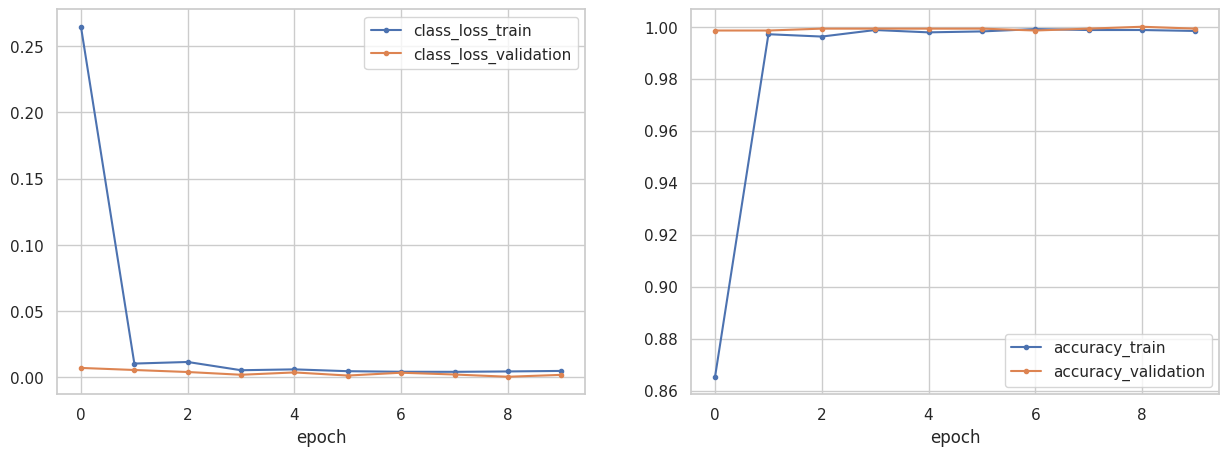

In [92]:
model_name = 'scgpt-spatial'

for outer_fold in [1]:
    model, test_acc = single_train_test_pipeline(
                            sample_key,
                            classification_key,
                            dataset_name,
                            model_name,
                            outer_fold,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_idx += 1

In [24]:
pd.DataFrame(results)

,method,Accuracy,F1,dataset
0,Novae,0.534254,0.579102,Sample
1,Novae,0.549244,0.617532,Sample
2,Novae,0.610597,0.662482,Sample
3,Novae,0.607420,0.639426,Sample
4,Novae,0.529897,0.574567,Sample
5,scGPT-spatial,0.902253,0.898809,Sample
6,scGPT-spatial,0.891726,0.894448,Sample
7,scGPT-spatial,0.730147,0.764916,Sample
8,scGPT-spatial,0.758824,0.765877,Sample
9,scGPT-spatial,0.777163,0.788432,Sample


## Terra (Cell Embeddings)

In [16]:
model_name = 'pantheome-cell'

for outer_fold in [1]:
    model, test_acc, test_f1 = single_train_test_pipeline(
                            sample_key,
                            classification_key,
                            dataset_name,
                            model_name,
                            outer_fold,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    # results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_dict = {
        'method': "TERRA-Cell",
        'Accuracy': test_acc,
        'F1': test_f1,
        'dataset': 'Xenium\n Eczema',
    }
    results.append(row_dict)
    row_idx += 1

AnnData setup complete!
Trainval Adata Shape: (891365, 384)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (244365, 384)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:27<00:00, 14.76s/it, loss=0.00182, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:27<00:00, 14.74s/it, loss=0.00182, v_num=1]
Training complete!
Model: pantheome-cell | Fold: 1
Test Accuracy: 0.8366
Test F1: 0.8221
              precision    recall  f1-score   support

           0       0.87      0.94      0.90    198475
           1       0.60      0.39      0.47     45890

    accuracy                           0.84    244365
   macro avg       0.73      0.66      0.69    244365
weighted avg       0.82      0.84      0.82    244365



In [72]:
results

{'1': ['pantheome', 1, 0.6761197389151474],
 '2': ['pantheome', 2, 0.7995396150304731]}

## Terra (Neighborhood Embedding)

In [17]:
model_name = 'pantheome'

for outer_fold in [1,2,3,4,5]:
# for outer_fold in [1]:
    model, test_acc, test_f1 = single_train_test_pipeline(
                            sample_key,
                            classification_key,
                            dataset_name,
                            model_name,
                            outer_fold,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    # results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_dict = {
        'method': "TERRA",
        'Accuracy': test_acc,
        'F1': test_f1,
        'dataset': 'Sample',
    }
    results.append(row_dict)
    row_idx += 1

AnnData setup complete!
Trainval Adata Shape: (891365, 384)
AnnData setup complete!
Test Adata Shape: (244365, 384)
Model created!


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


Epoch 10/10: 100%|██████████| 10/10 [02:38<00:00, 15.84s/it, loss=0.000406, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:38<00:00, 15.88s/it, loss=0.000406, v_num=1]
Training complete!
Model: pantheome | Fold: 1
Test Accuracy: 0.8055
Test F1: 0.8181
              precision    recall  f1-score   support

           0       0.92      0.83      0.87    198475
           1       0.49      0.71      0.58     45890

    accuracy                           0.81    244365
   macro avg       0.71      0.77      0.73    244365
weighted avg       0.84      0.81      0.82    244365

AnnData setup complete!
Trainval Adata Shape: (907660, 384)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


... (11 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (242419, 384)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:39<00:00, 15.96s/it, loss=0.000167, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:39<00:00, 15.98s/it, loss=0.000167, v_num=1]
Training complete!
Model: pantheome | Fold: 5
Test Accuracy: 0.7545
Test F1: 0.7751
              precision    recall  f1-score   support

           0       0.92      0.76      0.83    195657
           1       0.42      0.71      0.53     46762

    accuracy                           0.75    242419
   macro avg       0.67      0.74      0.68    242419
weighted avg       0.82      0.75      0.78    242419



In [15]:
results

[{'method': 'scGPT-spatial',
  'Accuracy': 0.8615431833527715,
  'F1': 0.8668274662153198,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.7979918446091112,
  'F1': 0.8238507477118431,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.7226683230560383,
  'F1': 0.7581949145261422,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.7051371287237069,
  'F1': 0.723449051003252,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.791225110243009,
  'F1': 0.8051743347695993,
  'dataset': 'Sample'},
 {'method': 'TERRA',
  'Accuracy': 0.8607656579297362,
  'F1': 0.8663325228616839,
  'dataset': 'Sample'},
 {'method': 'TERRA',
  'Accuracy': 0.7777875213750164,
  'F1': 0.8014253868194628,
  'dataset': 'Sample'},
 {'method': 'TERRA',
  'Accuracy': 0.850033311459643,
  'F1': 0.863054741008952,
  'dataset': 'Sample'},
 {'method': 'TERRA',
  'Accuracy': 0.7966817694311292,
  'F1': 0.8004121803393591,
  'dataset': 'Sample'},
 

## Terra (Cell + Neighbor)

In [29]:
model_name = 'pantheome-cell-nbr'

for outer_fold in [1,2,3,4,5]:
    model, test_acc, test_f1 = single_train_test_pipeline(
                            sample_key,
                            classification_key,
                            dataset_name,
                            model_name,
                            outer_fold,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    # results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_dict = {
        'method': "TERRA-Cell-Nbr",
        'Accuracy': test_acc,
        'F1': test_f1,
        'dataset': 'Sample',
    }
    results.append(row_dict)
    row_idx += 1

AnnData setup complete!
Trainval Adata Shape: (891365, 768)
AnnData setup complete!
Test Adata Shape: (244365, 768)
Model created!


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


Epoch 10/10: 100%|██████████| 10/10 [02:30<00:00, 15.02s/it, loss=0.000133, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:30<00:00, 15.03s/it, loss=0.000133, v_num=1]
Training complete!
Model: pantheome-cell-nbr | Fold: 1
Test Accuracy: 0.7937
Test F1: 0.8069
              precision    recall  f1-score   support

           0       0.92      0.82      0.87    198475
           1       0.47      0.67      0.55     45890

    accuracy                           0.79    244365
   macro avg       0.69      0.75      0.71    244365
weighted avg       0.83      0.79      0.81    244365

AnnData setup complete!
Trainval Adata Shape: (907660, 768)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


... (11 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (242419, 768)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:31<00:00, 15.20s/it, loss=0.0267, v_num=1]  

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:31<00:00, 15.20s/it, loss=0.0267, v_num=1]
Training complete!
Model: pantheome-cell-nbr | Fold: 5
Test Accuracy: 0.7872
Test F1: 0.7955
              precision    recall  f1-score   support

           0       0.89      0.84      0.86    195657
           1       0.46      0.57      0.51     46762

    accuracy                           0.79    242419
   macro avg       0.67      0.70      0.69    242419
weighted avg       0.81      0.79      0.80    242419



## CellPLM

In [27]:
model_name = 'cellplm'

for outer_fold in [1,2,3,4,5]:
    model, test_acc, test_f1 = single_train_test_pipeline(
                            sample_key,
                            classification_key,
                            dataset_name,
                            model_name,
                            outer_fold,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    # results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_dict = {
        'method': "CellPLM",
        'Accuracy': test_acc,
        'F1': test_f1,
        'dataset': 'Sample',
    }
    results.append(row_dict)
    row_idx += 1

AnnData setup complete!
Trainval Adata Shape: (891365, 512)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (244365, 512)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:28<00:00, 14.82s/it, loss=0.13, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:28<00:00, 14.88s/it, loss=0.13, v_num=1]
Training complete!
Model: cellplm | Fold: 1
Test Accuracy: 0.7902
Test F1: 0.8001
              precision    recall  f1-score   support

           0       0.90      0.84      0.87    198475
           1       0.45      0.59      0.51     45890

    accuracy                           0.79    244365
   macro avg       0.68      0.71      0.69    244365
weighted avg       0.82      0.79      0.80    244365

AnnData setup complete!
Trainval Adata Shape: (907660, 512)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


... (11 outputs left out)

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.2g.20gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-920c7c71-7a0d-fa0e-70ba-0f3145b82db9/5/0]


AnnData setup complete!
Test Adata Shape: (242419, 512)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:29<00:00, 14.96s/it, loss=0.172, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:29<00:00, 14.92s/it, loss=0.172, v_num=1]
Training complete!
Model: cellplm | Fold: 5
Test Accuracy: 0.6481
Test F1: 0.6849
              precision    recall  f1-score   support

           0       0.90      0.63      0.74    195657
           1       0.32      0.72      0.44     46762

    accuracy                           0.65    242419
   macro avg       0.61      0.67      0.59    242419
weighted avg       0.79      0.65      0.68    242419



In [28]:
results

[{'method': 'Novae',
  'Accuracy': 0.5342540871237698,
  'F1': 0.5791016560546366,
  'dataset': 'Sample'},
 {'method': 'Novae',
  'Accuracy': 0.5492436532643487,
  'F1': 0.6175318511482504,
  'dataset': 'Sample'},
 {'method': 'Novae',
  'Accuracy': 0.6105965506359233,
  'F1': 0.662481732929866,
  'dataset': 'Sample'},
 {'method': 'Novae',
  'Accuracy': 0.6074200538446385,
  'F1': 0.6394257037237473,
  'dataset': 'Sample'},
 {'method': 'Novae',
  'Accuracy': 0.5298965840136293,
  'F1': 0.5745671695418196,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.9022527776072679,
  'F1': 0.8988088315298259,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.891726224404788,
  'F1': 0.8944477302449305,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.730147121439055,
  'F1': 0.7649160875461557,
  'dataset': 'Sample'},
 {'method': 'scGPT-spatial',
  'Accuracy': 0.7588241731783658,
  'F1': 0.7658771002602194,
  'dataset': 'Sample'},
 {'metho

## Plots

In [122]:
results

{'1': ['scgpt-spatial', 1, 0.822924723262333],
 '2': ['scgpt-spatial', 2, 0.8221861709124392],
 '3': ['scgpt-spatial', 3, 0.8317646056975119],
 '4': ['scgpt-spatial', 4, 0.6909624181933591],
 '5': ['scgpt-spatial', 5, 0.7817580305174099],
 '6': ['pantheome', 1, 0.8396128741841098],
 '7': ['pantheome', 2, 0.8672425132634718],
 '8': ['pantheome', 3, 0.8240704099062771],
 '9': ['pantheome', 4, 0.7024711624751023],
 '10': ['pantheome', 5, 0.7954863273918299],
 '27': ['novae', 1, 0.6927915208806499],
 '28': ['novae', 2, 0.6126057789275222],
 '29': ['novae', 3, 0.4830862942128227],
 '30': ['novae', 4, 0.5847659071508307],
 '31': ['novae', 5, 0.6600225229870595]}

In [81]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

def plot_outer_fold_samples_annotate_split_cells():
    # fold, disease, train_samples, test_samples, train_cells, test_cells
    data = [
        (1, "AD", 36, 11, 580_925, 198_475),
        (1, "Psoriasis", 24, 3, 310_440, 45_890),
        (2, "AD", 36, 11, 583_400, 196_000),
        (2, "Psoriasis", 24, 3, 324_260, 32_070),
        (3, "AD", 36, 11, 611_178, 168_222),
        (3, "Psoriasis", 23, 4, 324_921, 31_409),
        (4, "AD", 35, 12, 602_035, 177_365),
        (4, "Psoriasis", 23, 4, 305_260, 51_070),
        (5, "AD", 36, 11, 583_743, 195_657),
        (5, "Psoriasis", 23, 4, 309_568, 46_762),
    ]

    data = [
    # fold, disease, train_val_cells, train_val_samples, test_cells, test_samples
#     (1, "AD",         502_354, 30, 277_046, 17),
#     (1, "Psoriasis",  262_150, 19,  94_180,  8),

#     (2, "AD",         475_623, 28, 303_777, 19),
#     (2, "Psoriasis",  280_180, 21,  76_150,  6),

#     (3, "AD",         541_724, 32, 237_676, 15),
#     (3, "Psoriasis",  221_461, 18, 134_869,  9),
#     ]
    
    df = pd.DataFrame(
        data,
        columns=["Fold", "Disease", "TrainSamples", "TestSamples", "TrainCells", "TestCells"]
    )

    folds = sorted(df["Fold"].unique())
    x = list(range(len(folds)))
    width = 0.35
    colors = {"AD": "#4C72B0", "Psoriasis": "#DD8452"}

    fig, ax = plt.subplots(figsize=(12, 6))

    for disease, offset in [("AD", -width/2), ("Psoriasis", width/2)]:
        sub = df[df["Disease"] == disease].set_index("Fold").loc[folds]
        xpos = [xi + offset for xi in x]

        train = ax.bar(
            xpos, sub["TrainSamples"].to_numpy(), width,
            color=colors[disease], alpha=1.0
        )
        test = ax.bar(
            xpos, sub["TestSamples"].to_numpy(), width,
            bottom=sub["TrainSamples"].to_numpy(),
            color=colors[disease], alpha=0.5
        )

        # annotate TRAIN segment with train cells
        for patch, cells in zip(train.patches, sub["TrainCells"].to_numpy()):
            ax.text(
                patch.get_x() + patch.get_width()/2,
                patch.get_y() + patch.get_height()/2,
                f"{cells:,}",
                ha="center", va="center", fontsize=8
            )

        # annotate TEST segment with test cells
        for patch, cells in zip(test.patches, sub["TestCells"].to_numpy()):
            ax.text(
                patch.get_x() + patch.get_width()/2,
                patch.get_y() + patch.get_height()/2,
                f"{cells:,}",
                ha="center", va="center", fontsize=8
            )

    ax.set_xticks(x)
    ax.set_xticklabels(folds)
    ax.set_xlabel("Fold")
    ax.set_ylabel("Number of Samples")
    ax.set_title("Samples per Fold")

    disease_legend = [Patch(facecolor=colors["AD"], label="AD"),
                      Patch(facecolor=colors["Psoriasis"], label="Psoriasis")]
    split_legend = [Patch(facecolor="gray", alpha=1.0, label="Train+Val"),
                    Patch(facecolor="gray", alpha=0.5, label="Test")]

    leg1 = ax.legend(handles=disease_legend, title="Disease", loc="upper left")
    ax.add_artist(leg1)
    ax.legend(handles=split_legend, title="Split", loc="upper right")

    plt.tight_layout()
    plt.show()


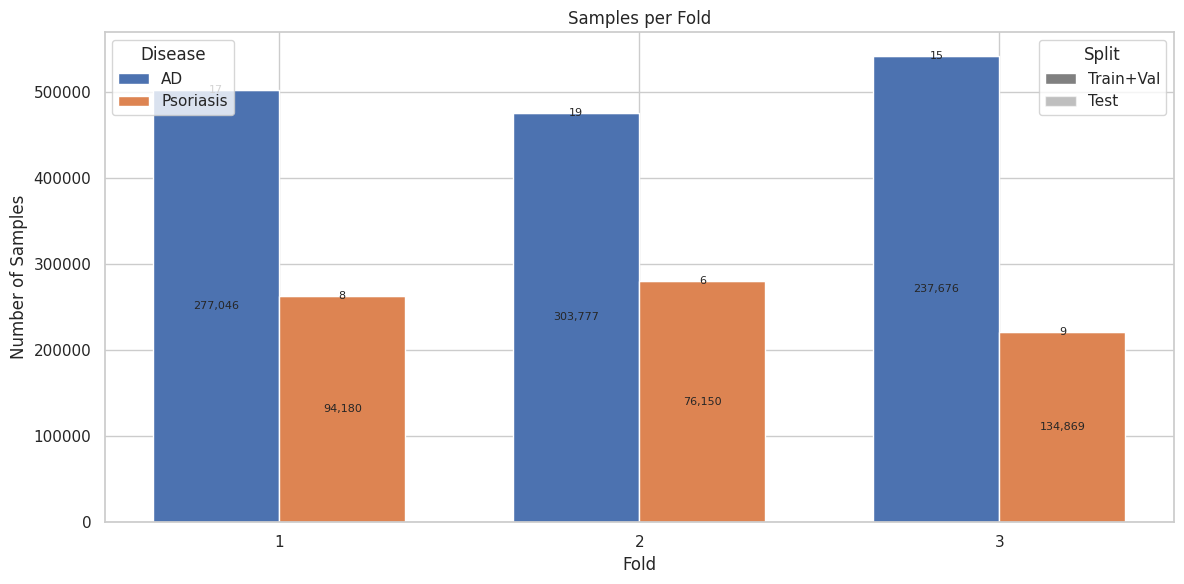

In [82]:
plot_outer_fold_samples_annotate_split_cells()

In [8]:
data = {
    "Novae": [
        0.6927915208806499,
        0.6126057789275222,
        0.4830862942128227,
        0.5847659071508307,
        0.6600225229870595,
    ],
    "scGPT-spatial": [
        0.822924723262333,
        0.8221861709124392,
        0.8317646056975119,
        0.6909624181933591,
        0.7817580305174099,
    ],
    "TERRA": [
        0.8396128741841098,
        0.8672425132634718,
        0.8240704099062771,
        0.7024711624751023,
        0.7954863273918299,
    ],
}

In [11]:
df = pd.DataFrame(data)
df = df.melt(
    var_name='method',
    value_name='Accuracy',  # or 'ARI' depending on what metric these values represent
    ignore_index=False
).reset_index()
df['dataset'] = 'Xenium\n Eczema'
df

,index,method,Accuracy,dataset
0,0,Novae,0.692792,Xenium\n Eczema
1,1,Novae,0.612606,Xenium\n Eczema
2,2,Novae,0.483086,Xenium\n Eczema
3,3,Novae,0.584766,Xenium\n Eczema
4,4,Novae,0.660023,Xenium\n Eczema
5,0,scGPT-spatial,0.822925,Xenium\n Eczema
6,1,scGPT-spatial,0.822186,Xenium\n Eczema
7,2,scGPT-spatial,0.831765,Xenium\n Eczema
8,3,scGPT-spatial,0.690962,Xenium\n Eczema
9,4,scGPT-spatial,0.781758,Xenium\n Eczema


NameError: name 'benchmarking_artifacts_folder_path' is not defined

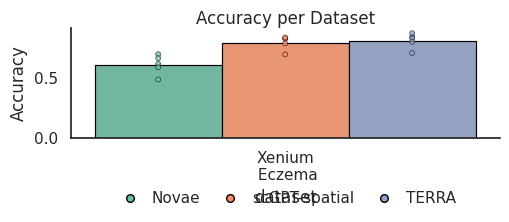

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict
from matplotlib.lines import Line2D

# ----------------------------
# Nature-style rcParams
# ----------------------------
plt.rcParams.update({
    "font.size": 21,
    "axes.titlesize": 21,
    "axes.labelsize": 21,
    "xtick.labelsize": 19,
    "ytick.labelsize": 19,
    "legend.fontsize": 17,
    "axes.linewidth": 1.1,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none"
})

sns.set(style="white")

for metric in ["Accuracy"]:
    fig, ax = plt.subplots(figsize=(4.9, 2.0))

    palette = "Set2"

    # ---- BARPLOT (default width to match stripplot) ----
    sns.barplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        palette=palette,
        dodge=True,
        ci=None,
        width=0.8,
        edgecolor="black",
        linewidth=0.85,
        ax=ax
    )

    # ---- POINTS (CENTERED, NO JITTER) ----
    sns.stripplot(
        x="dataset",
        y=metric,
        hue="method",
        data=df,
        dodge=True,
        jitter=False,
        size=3.6,
        marker="o",
        edgecolor="black",
        linewidth=0.45,
        alpha=0.75,
        palette=palette,
        ax=ax
    )

    # ---- CLEAN LEGEND (SINGLE ROW, CENTERED) ----
    handles, labels = ax.get_legend_handles_labels()
    by_label = OrderedDict(zip(labels, handles))
    if ax.legend_ is not None:
        ax.legend_.remove()

    methods = list(by_label.keys())
    colors = sns.color_palette(palette, len(methods))

    custom_handles = [
        Line2D(
            [0], [0],
            marker="o",
            linestyle="",
            color="w",
            label=m,
            markerfacecolor=colors[i],
            markeredgecolor="black",
            markersize=5.5
        )
        for i, m in enumerate(methods)
    ]

    ax.legend(
        handles=custom_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.36),
        ncol=len(custom_handles),
        frameon=False,
        handletextpad=0.4,
        columnspacing=1.0
    )

    # ---- AXES ----
    ax.set_title(f"{metric} per Dataset", pad=3)
    #ax.set_xlabel("Dataset", labelpad=3)
    #ax.set_ylabel("")              # 🔑 remove y-axis label

    # Optional dataset separators
    for i in range(df["dataset"].nunique() - 1):
        ax.axvline(i + 0.5, color="black", linestyle="--", linewidth=0.9, zorder=0)

    # ---- WHITESPACE REMOVAL ----
    sns.despine(ax=ax, top=True, right=True)
    ax.grid(False)

    n = df["dataset"].nunique()
    ax.set_xlim(-0.45, n - 0.55)
    ax.margins(x=0)

    plt.tight_layout(pad=0.01)
    plt.subplots_adjust(bottom=0.36)

    # ---- SAVE ----
    # plt.savefig(
    #     f"{benchmarking_artifacts_folder_path}/figures/"
    #     f"benchmarking_comparison_{metric.lower()}_{nichejepa_model_timestamp}.svg",
    #     dpi=300,
    #     bbox_inches="tight"
    # )
    plt.show()

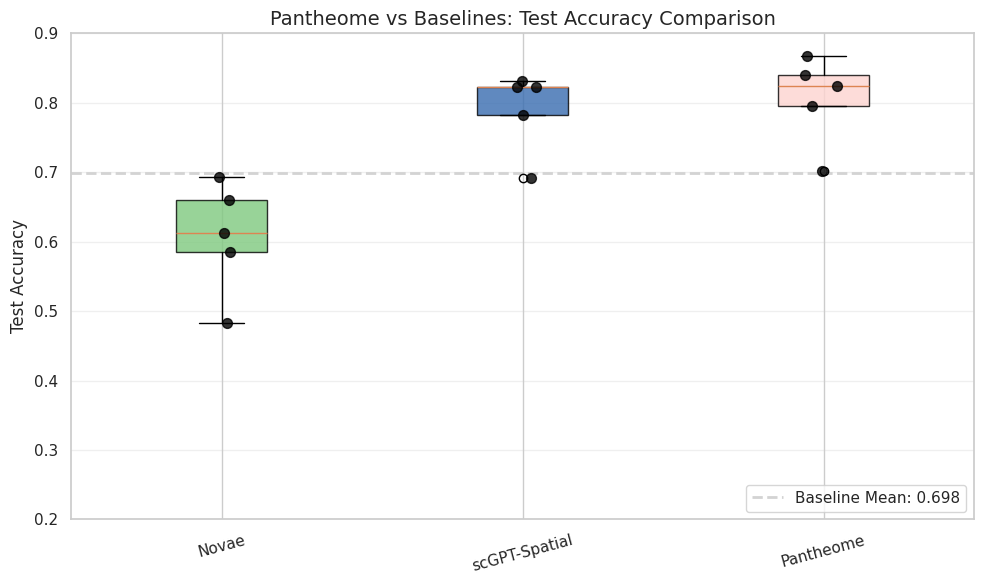

In [132]:
# Create DataFrame
df = pd.DataFrame(data)        

# Create the box plot
fig, ax = plt.subplots(figsize=(10, 6))

# Get specific colors from Accent palette (green=0, red=3, blue=4)
accent = sns.color_palette("Accent")
green = accent[0]   # For Novae or other baselines
blue = accent[4]    # For scGPT-spatial Zero-shot
red = accent[3]     # Reserve for future baselines

# Get three shades from RdPu for Pantheome methods (light to dark)
rdpu = sns.color_palette("RdPu", n_colors=10)
pantheome_light = rdpu[1]   # Pantheome Zero-shot
pantheome_mid = rdpu[4]     # Pantheome Linear Probing  
pantheome_dark = rdpu[8]    # Pantheome LoRA + Linear Probing

# Combine: [Novae, Pantheome Zero-shot, Pantheome LP, Pantheome LoRA+LP]
colors = [green, blue, pantheome_light]
# colors = [green, pantheome_light, pantheome_mid, pantheome_dark]

bp = ax.boxplot(df.values, labels=df.columns, patch_artist=True)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

# Scatter points
for i, col in enumerate(df.columns):
    y = df[col]
    x = np.random.normal(i + 1, 0.04, size=len(y))
    ax.scatter(x, y, alpha=0.8, color='black', s=50, zorder=3)

# Calculate mean of means for non-Pantheome baselines
baseline_columns = ['Novae', 'scGPT-Spatial']
baseline_mean_of_means = df[baseline_columns].mean().mean()

# Draw horizontal line for baseline mean
ax.axhline(y=baseline_mean_of_means, color='lightgray', linestyle='--', linewidth=2, 
           label=f'Baseline Mean: {baseline_mean_of_means:.3f}', zorder=1)

ax.set_ylabel('Test Accuracy', fontsize=12)
ax.set_title('Pantheome vs Baselines: Test Accuracy Comparison', fontsize=14)
ax.set_ylim(0.2, 0.9)
ax.grid(axis='y', alpha=0.3)
ax.tick_params(axis='x', rotation=15)
ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

# Archive

In [73]:
outer_fold = 1

train_adata_1 = sc.read_h5ad(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/data/outer-fold_1/train.h5ad")
test_adata_1 = sc.read_h5ad(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/data/outer-fold_1/test.h5ad")

train_adata_2 = sc.read_h5ad(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_disease-classification-patient/data/outer-fold_{outer_fold}/train.h5ad")
test_adata_2 = sc.read_h5ad(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_disease-classification-patient/data/outer-fold_{outer_fold}/test.h5ad")

# -----------------------------
# Load embeddings
# -----------------------------
train_emb_1 = np.load(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/model_artifacts/pantheome-zeroshot/outer-fold_1/train_cell_features.npy")
test_emb_1  = np.load(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_niche-transfer/model_artifacts/pantheome-zeroshot/outer-fold_1/test_cell_features.npy")

# -----------------------------
# Extract cell IDs
# -----------------------------
train_ids_1 = train_adata_1.obs["cell_id"].tolist()
test_ids_1  = test_adata_1.obs["cell_id"].tolist()

# Sanity checks
assert len(train_emb_1) == len(train_ids_1)
assert len(test_emb_1) == len(test_ids_1)

# -----------------------------
# Build cell_id → embedding map
# -----------------------------
cellid_to_emb = {}

for cid, emb in zip(train_ids_1, train_emb_1):
    cellid_to_emb[cid] = emb

for cid, emb in zip(test_ids_1, test_emb_1):
    if cid in cellid_to_emb:
        raise ValueError(f"Duplicate cell_id found: {cid}")
    cellid_to_emb[cid] = emb

# -----------------------------
# Reconstruct embeddings for split 2
# -----------------------------
train_ids_2 = train_adata_2.obs["cell_id"].tolist()
test_ids_2  = test_adata_2.obs["cell_id"].tolist()

# Ensure all cells exist
missing_train = set(train_ids_2) - cellid_to_emb.keys()
missing_test  = set(test_ids_2)  - cellid_to_emb.keys()

assert len(missing_train) == 0, f"Missing train cells: {missing_train}"
assert len(missing_test)  == 0, f"Missing test cells: {missing_test}"

# Stack embeddings in the correct order
train_emb_2 = np.stack([cellid_to_emb[cid] for cid in train_ids_2])
test_emb_2  = np.stack([cellid_to_emb[cid] for cid in test_ids_2])

print(train_adata_2.shape, train_emb_2.shape)
print(test_adata_2.shape, test_emb_2.shape)
# -----------------------------
# Save
# -----------------------------
# np.save("train_emb_2.npy", train_emb_2.astype(np.float32))
# np.save("test_emb_2.npy",  test_emb_2.astype(np.float32))


(671480, 4993) (671480, 384)
(464250, 4993) (464250, 384)


In [52]:
def single_modified_train_test_pipeline(
        sample_key,
        classification_key,
        model_name,
        outer_fold,
        trainval_adata,
        test_adata,
        trainval_embeddings,
        test_embeddings
    ):
    ##################################
    # 1. Prepare Train-Val Adata
    ##################################

    # trainval_adata_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_disease-classification-patient/data/outer-fold_{outer_fold}/train.h5ad")
    # trainval_adata = sc.read_h5ad(trainval_adata_path)

    # Load embeddings
    # trainval_emb_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_disease-classification-patient/model_artifacts/{model_name}-zeroshot/outer-fold_{outer_fold}/train_features.npy")
    # trainval_embeddings = np.load(trainval_emb_path)
    
    trainval_adata = create_anndata_from_embeddings(
            trainval_embeddings,
            trainval_adata,
            sample_key,
            classification_key
        )

    print(f"Trainval Adata Shape: {trainval_adata.shape}")

    ##################################
    # 2. Prepare Test Adata
    ##################################
    
    # test_adata_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_disease-classification-patient/data/outer-fold_{outer_fold}/test.h5ad")
    # test_adata = sc.read_h5ad(test_adata_path)

    # Load embeddings
    # test_emb_path = Path(f"/lustre/scratch126/cellgen/lotfollahi/am84/NEMO/data/xhs_disease-classification-patient/model_artifacts/{model_name}-zeroshot/outer-fold_{outer_fold}/test_features.npy")
    # test_embeddings = np.load(test_emb_path)

    test_adata = create_anndata_from_embeddings(
        test_embeddings,
        test_adata,
        sample_key,
        classification_key
    )
    
    print(f"Test Adata Shape: {test_adata.shape}")
    
    ##################################
    # 3. Train MIL
    ##################################

    model = train_MIL(
            trainval_adata,
            sample_key,
            classification_key
        )
    print(f"Model: {model_name} | Fold: {outer_fold}")
    
    ##################################
    # 4. Test MIL
    ##################################

    test_accuracy = evaluate_model(
        model,
        test_adata,
        classification_key,
    )
    
    return model, test_accuracy

AnnData setup complete!
Trainval Adata Shape: (671480, 384)


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-SXM4-80GB MIG 1c.4g.40gb') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [MIG-GPU-65984e58-2b6b-21f8-41cd-7854ff83d259/2/0]


AnnData setup complete!
Test Adata Shape: (464250, 384)
Model created!
Epoch 10/10: 100%|██████████| 10/10 [02:05<00:00, 12.59s/it, loss=0.000102, v_num=1]

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [02:05<00:00, 12.56s/it, loss=0.000102, v_num=1]
Training complete!
Model: terra | Fold: 2
Test Accuracy: 0.5659
Test F1: 0.5665
              precision    recall  f1-score   support

           0       0.61      0.59      0.60    254752
           1       0.52      0.54      0.53    209498

    accuracy                           0.57    464250
   macro avg       0.56      0.56      0.56    464250
weighted avg       0.57      0.57      0.57    464250



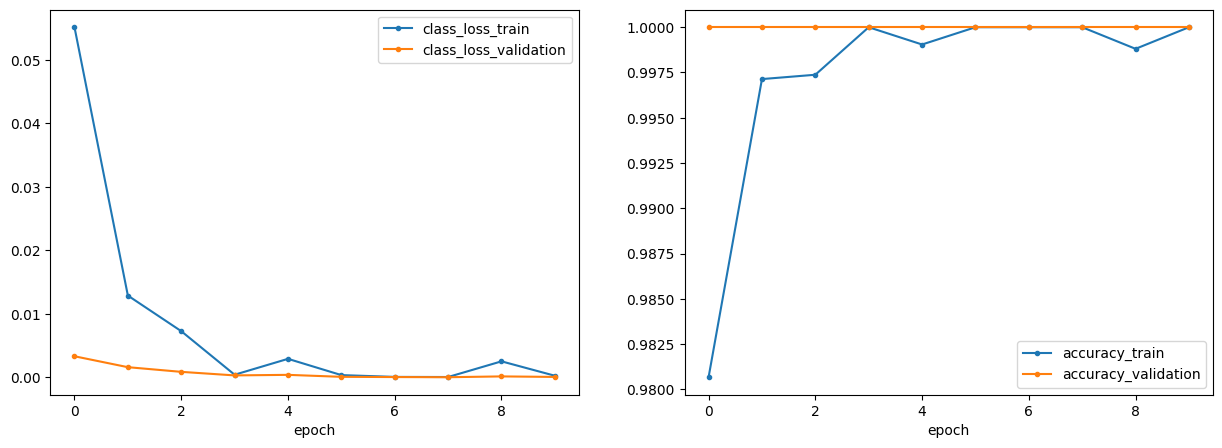

In [74]:
model_name = 'terra'

for outer_fold in [2]:
    model, test_acc = single_modified_train_test_pipeline(
                            sample_key,
                            classification_key,
                            model_name,
                            outer_fold,
                            train_adata_2,
                            test_adata_2,
                            train_emb_2,
                            test_emb_2,
                        )
    model_instances.update({f"{row_idx}": [model_name, outer_fold, model]})
    results.update({f"{row_idx}": [model_name, outer_fold, test_acc]})
    row_idx += 1

In [67]:
del results['5']
row_idx = 5

In [75]:
results

{'1': ['scgpt-spatial', 1, 0.5821217016693592],
 '2': ['scgpt-spatial', 2, 0.6553106570560553],
 '3': ['novae', 1, 0.5487388260635433],
 '4': ['novae', 2, 0.5533388931911598],
 '5': ['terra', 2, 0.7151024602370882],
 '6': ['terra', 2, 0.5658546042003231]}